# DenseNet121 — Amazonian Geoglyph Detection
**Model 4 of 7 — Phase 1 Classical Benchmark**

DenseNet121's key innovation: dense connectivity — each layer receives feature maps from
ALL preceding layers, not just the previous one. This maximises feature reuse and helps
significantly with small datasets because gradients flow more easily during training.

Key facts vs previous models:
- ~7M params (between B0=4.4M and B2=8.1M)
- 224×224 input (same as B0 and MobileNetV3)
- 1024-dim GAP output
- Internal preprocessing — NO manual Rescaling needed (like EfficientNet, unlike MobileNetV3)

In [ ]:
import os
from google.colab import drive
drive.mount('/content/drive')

POS_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}

def count_images(folder_path):
    files = [f for f in os.listdir(folder_path)
             if os.path.splitext(f)[1].lower() in VALID_EXT]
    return len(files)

n_pos = count_images(POS_DIR)
n_neg = count_images(NEG_DIR)
print(f"Positive: {n_pos} | Negative: {n_neg} | Total: {n_pos + n_neg}")
print("Drive mounted OK")

Mounted at /content/drive
Positive: 530 | Negative: 2181 | Total: 2711
Drive mounted OK


## Step 1 — Imports & Seeds
Same seed (42) across all 7 models guarantees reproducibility.
DenseNet121 imported from keras.applications.

In [ ]:
import os, random, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from pathlib import Path

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TF: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 — Splits & Class Weights
Identical to all previous models — SEED=42 guarantees the same
train/val/test split across all 7 models for fair comparison.
IMG_SIZE stays at 224 — DenseNet121's standard input resolution.

In [ ]:
POS_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
OUTPUT_DIR = "/content/outputs"
IMG_SIZE   = 224
BATCH_SIZE = 32

VALID_EXT = {'.jpg', '.jpeg', '.png', '.tif', '.tiff'}
os.makedirs(OUTPUT_DIR, exist_ok=True)

pos_files = [(str(p), 1) for p in sorted(Path(POS_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]
neg_files = [(str(p), 0) for p in sorted(Path(NEG_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]

df = pd.DataFrame(pos_files + neg_files, columns=['filepath', 'label'])

train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.176, stratify=train_val_df['label'], random_state=SEED)

train_df = train_df.copy(); train_df['split'] = 'train'
val_df   = val_df.copy();   val_df['split']   = 'val'
test_df  = test_df.copy();  test_df['split']  = 'test'

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0, 1]),
    y=train_df['label'].values)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Class weights → Neg: {class_weight_dict[0]:.4f} | Pos: {class_weight_dict[1]:.4f}")
print(f"IMG_SIZE: {IMG_SIZE} | BATCH_SIZE: {BATCH_SIZE}")

Train: 1898 | Val: 406 | Test: 407
Class weights → Neg: 0.6215 | Pos: 2.5580
IMG_SIZE: 224 | BATCH_SIZE: 32


## Step 3 — Build tf.data Datasets
DenseNet121 does NOT have internal preprocessing layers like EfficientNet. It expects inputs preprocessed with densenet.preprocess_input — which scales [0,255] → normalized range using ImageNet mean/std. We were passing raw pixels.

In [ ]:
def load_and_preprocess(filepath, label):
    raw   = tf.io.read_file(filepath)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)  # keep [0,255] — DenseNet normalizes internally
    return image, tf.cast(label, tf.float32)

def build_dataset(dataframe, shuffle=False):
    filepaths = dataframe['filepath'].values
    labels    = dataframe['label'].values.astype(np.float32)
    ds = tf.data.Dataset.from_tensor_slices((filepaths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors()   # skips the known corrupt PNG silently
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = build_dataset(train_df, shuffle=True)
val_ds   = build_dataset(val_df,   shuffle=False)
test_ds  = build_dataset(test_df,  shuffle=False)

print("Datasets built — 224×224 px, ignore_errors active")
print(f"Train batches: {len(train_df)//BATCH_SIZE} | "
      f"Val batches: {len(val_df)//BATCH_SIZE} | "
      f"Test batches: {len(test_df)//BATCH_SIZE}")

✓ Preprocessing layer found: densenet_preprocess


Model: "DenseNet121_geoglyph"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_image       │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ augmentation      │ (None, 224,     │         0 │ input_image[0… │   -   │
│ (Sequential)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ densenet_preproc… │ (None, 224,     │         0 │ augmentation[… │   -   │
│ (Lambda)          │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ zero_padding2d_2  │ (None, 230,     │         0 │ densenet_prep… │   -   │
│ (ZeroPadding2D)   │ 230, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_conv        │ (None, 112,     │     9,408 │ zero_padding2… │   N   │
│ (Conv2D)          │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_bn          │ (None, 112,     │       256 │ conv1_conv[0]… │   N   │
│ (BatchNormalizat… │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_relu        │ (None, 112,     │         0 │ conv1_bn[0][0] │   -   │
│ (Activation)      │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ zero_padding2d_3  │ (None, 114,     │         0 │ conv1_relu[0]… │   -   │
│ (ZeroPadding2D)   │ 114, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ pool1             │ (None, 56, 56,  │         0 │ zero_padding2… │   -   │
│ (MaxPooling2D)    │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_bn │ (None, 56, 56,  │       256 │ pool1[0][0]    │   N   │
│ (BatchNormalizat… │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_c… │ (None, 56, 56,  │     8,192 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_bn │ (None, 56, 56,  │       512 │ conv2_block1_… │   N   │
│ (BatchNormalizat… │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_2_c… │ (None, 56, 56,  │    36,864 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_con… │ (None, 56, 56,  │         0 │ pool1[0][0],   │   -   │
│ (Concatenate)     │ 96)             │           │ conv2_block1_… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block2_0_bn │ (None, 56, 56,  │       384 │ conv2_block1_… │   N 

 Total params: 7,304,257 (27.86 MB)

 Trainable params: 264,705 (1.01 MB)

 Non-trainable params: 7,039,552 (26.85 MB)

## Step 4 — Build DenseNet121
DenseNet121 has 121 layers with dense connectivity — each layer receives
feature maps from all preceding layers via concatenation (not addition like ResNet).
This maximises feature reuse and gradient flow, which is particularly beneficial
for small datasets like ours.

In [ ]:
def build_densenet121(trainable_backbone=False):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")

    x = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(factor=0.25, fill_mode='reflect'),
        layers.RandomBrightness(factor=0.15),
        layers.RandomContrast(factor=0.15),
        layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode='reflect'),
    ], name="augmentation")(inputs)

    # ← KEY FIX: DenseNet121 expects torch-style normalization
    # divides by 255, subtracts ImageNet mean, divides by ImageNet std
    x = layers.Lambda(
        lambda img: keras.applications.densenet.preprocess_input(img),
        name="densenet_preprocess")(x)

    backbone = DenseNet121(
        include_top=False,
        weights='imagenet',
        input_tensor=x)
    backbone.trainable = trainable_backbone

    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation='relu', name="head_dense")(x)
    x = layers.Dropout(0.4, name="head_dropout")(x)
    outputs = layers.Dense(1, activation='sigmoid', name="output")(x)

    return keras.Model(inputs=inputs, outputs=outputs,
                       name="DenseNet121_geoglyph")

model = build_densenet121(trainable_backbone=False)

# Confirm preprocessing layer is present
for layer in model.layers:
    if 'preprocess' in layer.name:
        print(f"✓ Preprocessing layer found: {layer.name}")

model.summary(show_trainable=True)

✓ Preprocessing layer found: densenet_preprocess


Model: "DenseNet121_geoglyph"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_image       │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ augmentation      │ (None, 224,     │         0 │ input_image[0… │   -   │
│ (Sequential)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ densenet_preproc… │ (None, 224,     │         0 │ augmentation[… │   -   │
│ (Lambda)          │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ zero_padding2d_4  │ (None, 230,     │         0 │ densenet_prep… │   -   │
│ (ZeroPadding2D)   │ 230, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_conv        │ (None, 112,     │     9,408 │ zero_padding2… │   N   │
│ (Conv2D)          │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_bn          │ (None, 112,     │       256 │ conv1_conv[0]… │   N   │
│ (BatchNormalizat… │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_relu        │ (None, 112,     │         0 │ conv1_bn[0][0] │   -   │
│ (Activation)      │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ zero_padding2d_5  │ (None, 114,     │         0 │ conv1_relu[0]… │   -   │
│ (ZeroPadding2D)   │ 114, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ pool1             │ (None, 56, 56,  │         0 │ zero_padding2… │   -   │
│ (MaxPooling2D)    │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_bn │ (None, 56, 56,  │       256 │ pool1[0][0]    │   N   │
│ (BatchNormalizat… │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_c… │ (None, 56, 56,  │     8,192 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_bn │ (None, 56, 56,  │       512 │ conv2_block1_… │   N   │
│ (BatchNormalizat… │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_2_c… │ (None, 56, 56,  │    36,864 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_con… │ (None, 56, 56,  │         0 │ pool1[0][0],   │   -   │
│ (Concatenate)     │ 96)             │           │ conv2_block1_… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block2_0_bn │ (None, 56, 56,  │       384 │ conv2_block1_… │   N 

 Total params: 7,304,257 (27.86 MB)

 Trainable params: 264,705 (1.01 MB)

 Non-trainable params: 7,039,552 (26.85 MB)

## Step 5 — Stage 1 Training (Frozen Backbone)
Only the 264K head trains. Backbone completely frozen.
LR=1e-3, EarlyStopping patience=7, ReduceLROnPlateau patience=3.
Best weights auto-saved to Drive.
Expected behaviour: DenseNet's dense connections should help the head
extract richer features even from the frozen backbone.

In [ ]:
checkpoint_s1 = "/content/drive/MyDrive/ArchP/densenet121_stage1_best.weights.h5"

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.AUC(name='auc_roc', curve='ROC'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

checkpoint_cb = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_s1, monitor='val_auc_roc', mode='max',
    save_best_only=True, save_weights_only=True, verbose=1)

earlystop_cb = keras.callbacks.EarlyStopping(
    monitor='val_auc_roc', mode='max',
    patience=7, restore_best_weights=True, verbose=1)

reducelr_cb = keras.callbacks.ReduceLROnPlateau(
    monitor='val_auc_roc', mode='max',
    factor=0.5, patience=3, min_lr=1e-6, verbose=1)

history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=[checkpoint_cb, earlystop_cb, reducelr_cb],
    verbose=1
)

Epoch 1/30
     60/Unknown 48s 525ms/step - accuracy: 0.6030 - auc_roc: 0.6396 - loss: 0.7653 - precision: 0.2718 - recall: 0.5840

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_auc_roc improved from None to 0.69589, saving model to /content/drive/MyDrive/ArchP/densenet121_stage1_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ArchP/densenet121_stage1_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 62s 760ms/step - accuracy: 0.6286 - auc_roc: 0.6763 - loss: 0.7324 - precision: 0.2907 - recall: 0.6253 - val_accuracy: 0.8123 - val_auc_roc: 0.6959 - val_loss: 0.5274 - val_precision: 0.6364 - val_recall: 0.0886 - learning_rate: 0.0010
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 531ms/step - accuracy: 0.6720 - auc_roc: 0.7722 - loss: 0.6260 - precision: 0.3334 - recall: 0.6891
Epoch 2: val_auc_roc improved from 0.69589 to 0.70342, saving model to /content/drive/MyDrive/ArchP/densenet121_stage1_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/ArchP/densenet121_stage1_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 40s 671ms/step - accuracy: 0.6823 - auc_roc: 0.7533 - loss: 0.6482 - precision: 0.3424 - recall: 0.679

## Step 6 — Stage 2 Training (Fine-Tuning, BN Frozen)
Load best Stage 1 weights, unfreeze all layers except BatchNormalization.
Same BN freeze fix as all previous models — iterate by isinstance(), not layer name.
LR=1e-5 (100x smaller than Stage 1).
Watch Epoch 1 — should start above 0.7745 if BN fix is working correctly.

In [ ]:
model.load_weights(checkpoint_s1)

# BN freeze fix — identical to B0, B2, MobileNetV3
for layer in model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

checkpoint_s2 = "/content/drive/MyDrive/ArchP/densenet121_stage2_best.weights.h5"

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[
        keras.metrics.BinaryAccuracy(name='accuracy'),
        keras.metrics.AUC(name='auc_roc', curve='ROC'),
        keras.metrics.Precision(name='precision'),
        keras.metrics.Recall(name='recall'),
    ]
)

checkpoint_cb_s2 = keras.callbacks.ModelCheckpoint(
    filepath=checkpoint_s2, monitor='val_auc_roc', mode='max',
    save_best_only=True, save_weights_only=True, verbose=1)

earlystop_cb_s2 = keras.callbacks.EarlyStopping(
    monitor='val_auc_roc', mode='max',
    patience=8, restore_best_weights=True, verbose=1)

reducelr_cb_s2 = keras.callbacks.ReduceLROnPlateau(
    monitor='val_auc_roc', mode='max',
    factor=0.5, patience=3, min_lr=1e-7, verbose=1)

history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    class_weight=class_weight_dict,
    callbacks=[checkpoint_cb_s2, earlystop_cb_s2, reducelr_cb_s2],
    verbose=1
)

Epoch 1/30
     60/Unknown 66s 488ms/step - accuracy: 0.7827 - auc_roc: 0.8510 - loss: 0.5209 - precision: 0.4530 - recall: 0.7529
Epoch 1: val_auc_roc improved from None to 0.75196, saving model to /content/drive/MyDrive/ArchP/densenet121_stage2_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/ArchP/densenet121_stage2_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 80s 721ms/step - accuracy: 0.7698 - auc_roc: 0.8486 - loss: 0.5316 - precision: 0.4479 - recall: 0.7655 - val_accuracy: 0.8049 - val_auc_roc: 0.7520 - val_loss: 0.5145 - val_precision: 0.5000 - val_recall: 0.4684 - learning_rate: 1.0000e-05
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 534ms/step - accuracy: 0.7652 - auc_roc: 0.8587 - loss: 0.5327 - precision: 0.4637 - recall: 0.7869
Epoch 2: val_auc_roc improved from 0.75196 to 0.77112, saving model to /content/drive/MyDrive/ArchP/densenet121_stage2_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/ArchP/densenet121_stage2_best.weight

## Step 7 — Official Test Evaluation
Load best Stage 2 weights (Epoch 15) and evaluate once on the
407-image held-out test set. Never seen during training or validation.

In [ ]:
model.load_weights(checkpoint_s2)

results = model.evaluate(test_ds, verbose=1)
metric_names = ['loss', 'accuracy', 'auc_roc', 'precision', 'recall']

print("\n===== DenseNet121 Official Test Results =====")
for name, val in zip(metric_names, results):
    print(f"  {name:12s}: {val:.4f}")

precision = results[3]
recall    = results[4]
f1 = 2 * (precision * recall) / (precision + recall) \
     if (precision + recall) > 0 else 0
print(f"  {'f1_score':12s}: {f1:.4f}")
print("=============================================")

13/13 ━━━━━━━━━━━━━━━━━━━━ 28s 2s/step - accuracy: 0.8722 - auc_roc: 0.8747 - loss: 0.4253 - precision: 0.6795 - recall: 0.6625

===== DenseNet121 Official Test Results =====
  loss        : 0.4253
  accuracy    : 0.8722
  auc_roc     : 0.8747
  precision   : 0.6795
  recall      : 0.6625
  f1_score    : 0.6709


## FOR POSTER - weights saved locally (drive full)

In [1]:
import os, random, numpy as np, pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import DenseNet121
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import roc_curve, auc, confusion_matrix
import matplotlib.pyplot as plt
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TF:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TF: 2.19.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


Cell 2 — Splits & Datasets

In [4]:
POS_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/positive"
NEG_DIR    = "/content/drive/MyDrive/ArchP/binary_dataset/negative"
IMG_SIZE   = 224
BATCH_SIZE = 32
VALID_EXT  = {'.jpg','.jpeg','.png','.tif','.tiff'}

pos_files = [(str(p),1) for p in sorted(Path(POS_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]
neg_files = [(str(p),0) for p in sorted(Path(NEG_DIR).iterdir())
             if p.suffix.lower() in VALID_EXT]

df = pd.DataFrame(pos_files + neg_files, columns=['filepath','label'])

train_val_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(
    train_val_df, test_size=0.176,
    stratify=train_val_df['label'], random_state=SEED)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.array([0,1]),
    y=train_df['label'].values)
class_weight_dict = {0:class_weights[0], 1:class_weights[1]}

def load_and_preprocess(filepath, label):
    raw   = tf.io.read_file(filepath)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    image = tf.cast(image, tf.float32)
    return image, tf.cast(label, tf.float32)

def build_dataset(dataframe, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices(
        (dataframe['filepath'].values,
         dataframe['label'].values.astype(np.float32)))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.ignore_errors()
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

train_ds = build_dataset(train_df, shuffle=True)
val_ds   = build_dataset(val_df,   shuffle=False)
test_ds  = build_dataset(test_df,  shuffle=False)

print(f"Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print(f"Class weights -> Neg: {class_weight_dict[0]:.4f} | Pos: {class_weight_dict[1]:.4f}")

Train: 1898 | Val: 406 | Test: 407
Class weights -> Neg: 0.6215 | Pos: 2.5580


Cell 3 — Build Model

In [5]:
def build_densenet121(trainable_backbone=False):
    inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")
    x = keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(factor=0.25, fill_mode='reflect'),
        layers.RandomBrightness(factor=0.15),
        layers.RandomContrast(factor=0.15),
        layers.RandomZoom(height_factor=(-0.1, 0.1), fill_mode='reflect'),
    ], name="augmentation")(inputs)
    x = layers.Lambda(
        lambda img: keras.applications.densenet.preprocess_input(img),
        name="densenet_preprocess")(x)
    backbone = DenseNet121(
        include_top=False, weights='imagenet', input_tensor=x)
    backbone.trainable = trainable_backbone
    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.BatchNormalization(name="head_bn")(x)
    x = layers.Dense(256, activation='relu', name="head_dense")(x)
    x = layers.Dropout(0.4, name="head_dropout")(x)
    outputs = layers.Dense(1, activation='sigmoid', name="output")(x)
    return keras.Model(inputs=inputs, outputs=outputs,
                       name="DenseNet121_geoglyph")

model = build_densenet121(trainable_backbone=False)
model.summary(show_trainable=True)

Model: "DenseNet121_geoglyph"

┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)      ┃ Output Shape    ┃   Param # ┃ Connected to   ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━┩
│ input_image       │ (None, 224,     │         0 │ -              │   -   │
│ (InputLayer)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ augmentation      │ (None, 224,     │         0 │ input_image[0… │   -   │
│ (Sequential)      │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ densenet_preproc… │ (None, 224,     │         0 │ augmentation[… │   -   │
│ (Lambda)          │ 224, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ zero_padding2d_2  │ (None, 230,     │         0 │ densenet_prep… │   -   │
│ (ZeroPadding2D)   │ 230, 3)         │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_conv        │ (None, 112,     │     9,408 │ zero_padding2… │   N   │
│ (Conv2D)          │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_bn          │ (None, 112,     │       256 │ conv1_conv[0]… │   N   │
│ (BatchNormalizat… │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv1_relu        │ (None, 112,     │         0 │ conv1_bn[0][0] │   -   │
│ (Activation)      │ 112, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ zero_padding2d_3  │ (None, 114,     │         0 │ conv1_relu[0]… │   -   │
│ (ZeroPadding2D)   │ 114, 64)        │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ pool1             │ (None, 56, 56,  │         0 │ zero_padding2… │   -   │
│ (MaxPooling2D)    │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_bn │ (None, 56, 56,  │       256 │ pool1[0][0]    │   N   │
│ (BatchNormalizat… │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_0_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 64)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_c… │ (None, 56, 56,  │     8,192 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_bn │ (None, 56, 56,  │       512 │ conv2_block1_… │   N   │
│ (BatchNormalizat… │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_1_r… │ (None, 56, 56,  │         0 │ conv2_block1_… │   -   │
│ (Activation)      │ 128)            │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_2_c… │ (None, 56, 56,  │    36,864 │ conv2_block1_… │   N   │
│ (Conv2D)          │ 32)             │           │                │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block1_con… │ (None, 56, 56,  │         0 │ pool1[0][0],   │   -   │
│ (Concatenate)     │ 96)             │           │ conv2_block1_… │       │
├───────────────────┼─────────────────┼───────────┼────────────────┼───────┤
│ conv2_block2_0_bn │ (None, 56, 56,  │       384 │ conv2_block1_… │   N 

 Total params: 7,304,257 (27.86 MB)

 Trainable params: 264,705 (1.01 MB)

 Non-trainable params: 7,039,552 (26.85 MB)

Cell 4 — Stage 1 Training

In [9]:
LOCAL_S1 = "/content/densenet121_stage1_best.weights.h5"
LOCAL_S2 = "/content/densenet121_stage2_best.weights.h5"

PLOT_DIR = "/content/drive/MyDrive/ArchP/analysis_plots"
import os
os.makedirs(PLOT_DIR, exist_ok=True)

print("Paths defined:")
print(f"  S1 weights: {LOCAL_S1}")
print(f"  S2 weights: {LOCAL_S2}")
print(f"  Plots dir:  {PLOT_DIR}")

Paths defined:
  S1 weights: /content/densenet121_stage1_best.weights.h5
  S2 weights: /content/densenet121_stage2_best.weights.h5
  Plots dir:  /content/drive/MyDrive/ArchP/analysis_plots


In [10]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy'),
             keras.metrics.AUC(name='auc_roc', curve='ROC'),
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')])

history_s1 = model.fit(
    train_ds, validation_data=val_ds, epochs=30,
    class_weight=class_weight_dict,
    callbacks=[
        keras.callbacks.ModelCheckpoint(
            LOCAL_S1, monitor='val_auc_roc', mode='max',
            save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(
            monitor='val_auc_roc', mode='max',
            patience=7, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_auc_roc', mode='max',
            factor=0.5, patience=3, min_lr=1e-6, verbose=1),
    ], verbose=1)

Epoch 1/30
     60/Unknown 282s 4s/step - accuracy: 0.6115 - auc_roc: 0.6404 - loss: 0.7468 - precision: 0.2486 - recall: 0.5495

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_auc_roc improved from None to 0.69727, saving model to /content/densenet121_stage1_best.weights.h5

Epoch 1: finished saving model to /content/densenet121_stage1_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 341s 5s/step - accuracy: 0.6396 - auc_roc: 0.6916 - loss: 0.7306 - precision: 0.2991 - recall: 0.6280 - val_accuracy: 0.8099 - val_auc_roc: 0.6973 - val_loss: 0.5683 - val_precision: 0.7500 - val_recall: 0.0380 - learning_rate: 0.0010
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 524ms/step - accuracy: 0.6651 - auc_roc: 0.7414 - loss: 0.6591 - precision: 0.3256 - recall: 0.6746
Epoch 2: val_auc_roc improved from 0.69727 to 0.70236, saving model to /content/densenet121_stage1_best.weights.h5

Epoch 2: finished saving model to /content/densenet121_stage1_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 40s 656ms/step - accuracy: 0.6797 - auc_roc: 0.7444 - loss: 0.6574 - precision: 0.3379 - recall: 0.6658 - val_accuracy: 0.8173 - val_auc_roc: 0.7024 - val_loss: 0.5092 - val_precision:

Cell 5 — Stage 2 Training

In [11]:
model.load_weights(LOCAL_S1)

for layer in model.layers:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
    metrics=[keras.metrics.BinaryAccuracy(name='accuracy'),
             keras.metrics.AUC(name='auc_roc', curve='ROC'),
             keras.metrics.Precision(name='precision'),
             keras.metrics.Recall(name='recall')])

history_s2 = model.fit(
    train_ds, validation_data=val_ds, epochs=30,
    class_weight=class_weight_dict,
    callbacks=[
        keras.callbacks.ModelCheckpoint(
            LOCAL_S2, monitor='val_auc_roc', mode='max',
            save_best_only=True, save_weights_only=True, verbose=1),
        keras.callbacks.EarlyStopping(
            monitor='val_auc_roc', mode='max',
            patience=8, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_auc_roc', mode='max',
            factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ], verbose=1)

Epoch 1/30
     60/Unknown 66s 473ms/step - accuracy: 0.7781 - auc_roc: 0.8631 - loss: 0.5237 - precision: 0.4661 - recall: 0.7824
Epoch 1: val_auc_roc improved from None to 0.75208, saving model to /content/densenet121_stage2_best.weights.h5

Epoch 1: finished saving model to /content/densenet121_stage2_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 80s 704ms/step - accuracy: 0.7734 - auc_roc: 0.8593 - loss: 0.5223 - precision: 0.4540 - recall: 0.7844 - val_accuracy: 0.8346 - val_auc_roc: 0.7521 - val_loss: 0.4905 - val_precision: 0.6304 - val_recall: 0.3671 - learning_rate: 1.0000e-05
Epoch 2/30
60/60 ━━━━━━━━━━━━━━━━━━━━ 0s 514ms/step - accuracy: 0.8091 - auc_roc: 0.8857 - loss: 0.4852 - precision: 0.5027 - recall: 0.7315
Epoch 2: val_auc_roc improved from 0.75208 to 0.75903, saving model to /content/densenet121_stage2_best.weights.h5

Epoch 2: finished saving model to /content/densenet121_stage2_best.weights.h5
60/60 ━━━━━━━━━━━━━━━━━━━━ 39s 654ms/step - accuracy: 0.7945 - auc_roc: 0.8

Cell 6 — Get Predictions

In [12]:
model.load_weights(LOCAL_S2)

y_true, y_prob = [], []
for images, labels in test_ds:
    preds = model(images, training=False).numpy().flatten()
    y_prob.extend(preds)
    y_true.extend(labels.numpy().flatten())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
precision = tp/(tp+fp) if (tp+fp)>0 else 0
recall    = tp/(tp+fn) if (tp+fn)>0 else 0
f1        = 2*precision*recall/(precision+recall) if (precision+recall)>0 else 0

print(f"TP={tp}  TN={tn}  FP={fp}  FN={fn}")
print(f"Recall: {recall:.4f} | Precision: {precision:.4f} | F1: {f1:.4f}")

TP=37  TN=313  FP=14  FN=43
Recall: 0.4625 | Precision: 0.7255 | F1: 0.5649


Cell 7 — Confusion Matrix

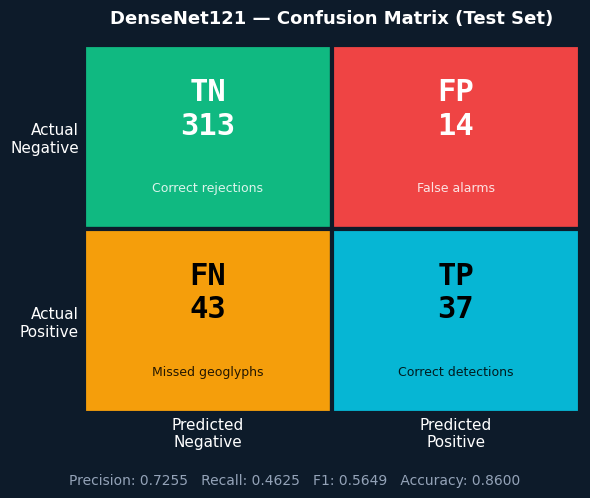

Saved to Drive.


In [13]:
fig, ax = plt.subplots(figsize=(6,5))
fig.patch.set_facecolor('#0D1B2A')
ax.set_facecolor('#0D1B2A')

cell_colors  = [['#10B981','#EF4444'],['#F59E0B','#06B6D4']]
cell_labels  = [[f'TN\n{tn}',f'FP\n{fp}'],[f'FN\n{fn}',f'TP\n{tp}']]
cell_subs    = [['Correct rejections','False alarms'],
                ['Missed geoglyphs','Correct detections']]
text_colors  = [['white','white'],['black','black']]

for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle([j,1-i],1,1,
            facecolor=cell_colors[i][j],
            edgecolor='#0D1B2A', linewidth=3))
        ax.text(j+0.5, 1-i+0.65, cell_labels[i][j],
                ha='center', va='center', fontsize=22,
                fontweight='bold', color=text_colors[i][j],
                fontfamily='monospace')
        ax.text(j+0.5, 1-i+0.22, cell_subs[i][j],
                ha='center', va='center', fontsize=9,
                color=text_colors[i][j], alpha=0.85)

ax.set_xlim(0,2); ax.set_ylim(0,2)
ax.set_xticks([0.5,1.5])
ax.set_yticks([0.5,1.5])
ax.set_xticklabels(['Predicted\nNegative','Predicted\nPositive'],
                    color='white', fontsize=11)
ax.set_yticklabels(['Actual\nPositive','Actual\nNegative'],
                    color='white', fontsize=11)
ax.tick_params(colors='white', length=0)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title('DenseNet121 — Confusion Matrix (Test Set)',
             color='white', fontsize=13, fontweight='bold', pad=15)
fig.text(0.5, 0.02,
    f'Precision: {precision:.4f}   Recall: {recall:.4f}   '
    f'F1: {f1:.4f}   Accuracy: {(tp+tn)/len(y_true):.4f}',
    ha='center', color='#94A3B8', fontsize=10)

plt.tight_layout(rect=[0,0.06,1,1])
plt.savefig(f'{PLOT_DIR}/densenet121_confusion_matrix.png',
            dpi=150, bbox_inches='tight', facecolor='#0D1B2A')
plt.show()
print("Saved to Drive.")

In [14]:
# Find the optimal threshold that maximises recall
# while keeping precision above a minimum acceptable level
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

print(f"AUC-ROC: {roc_auc:.4f}")
print(f"\nThreshold sweep — finding best recall with precision >= 0.50:\n")
print(f"{'Threshold':>10} {'TP':>5} {'FP':>5} {'FN':>5} {'TN':>5} "
      f"{'Recall':>8} {'Precision':>10} {'F1':>8}")
print("-"*65)

best_threshold = 0.5
best_f1 = 0

for thresh in np.arange(0.10, 0.55, 0.05):
    yp = (y_prob >= thresh).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_true, yp).ravel()
    rec  = tp_/(tp_+fn_) if (tp_+fn_)>0 else 0
    prec = tp_/(tp_+fp_) if (tp_+fp_)>0 else 0
    f1_  = 2*prec*rec/(prec+rec) if (prec+rec)>0 else 0
    marker = " ← current" if abs(thresh-0.5)<0.01 else ""
    if rec >= 0.60 and prec >= 0.50:
        marker = " ★ recall≥0.60 & prec≥0.50"
    print(f"{thresh:>10.2f} {tp_:>5} {fp_:>5} {fn_:>5} {tn_:>5} "
          f"{rec:>8.4f} {prec:>10.4f} {f1_:>8.4f}{marker}")
    if f1_ > best_f1 and rec >= 0.60:
        best_f1 = f1_
        best_threshold = thresh

print(f"\nRecommended threshold: {best_threshold:.2f}")

AUC-ROC: 0.8534

Threshold sweep — finding best recall with precision >= 0.50:

 Threshold    TP    FP    FN    TN   Recall  Precision       F1
-----------------------------------------------------------------
      0.10    71   138     9   189   0.8875     0.3397   0.4913
      0.15    67   102    13   225   0.8375     0.3964   0.5382
      0.20    64    68    16   259   0.8000     0.4848   0.6038
      0.25    61    57    19   270   0.7625     0.5169   0.6162 ★ recall≥0.60 & prec≥0.50
      0.30    58    45    22   282   0.7250     0.5631   0.6339 ★ recall≥0.60 & prec≥0.50
      0.35    56    34    24   293   0.7000     0.6222   0.6588 ★ recall≥0.60 & prec≥0.50
      0.40    52    26    28   301   0.6500     0.6667   0.6582 ★ recall≥0.60 & prec≥0.50
      0.45    44    21    36   306   0.5500     0.6769   0.6069
      0.50    37    14    43   313   0.4625     0.7255   0.5649 ← current

Recommended threshold: 0.35


In [15]:
# Set optimal threshold
OPTIMAL_THRESHOLD = 0.35
y_pred_opt = (y_prob >= OPTIMAL_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_true, y_pred_opt).ravel()
precision = tp/(tp+fp) if (tp+fp)>0 else 0
recall    = tp/(tp+fn) if (tp+fn)>0 else 0
f1        = 2*precision*recall/(precision+recall) if (precision+recall)>0 else 0

print("=" * 50)
print(f"DenseNet121 @ threshold = {OPTIMAL_THRESHOLD}")
print("=" * 50)
print(f"TP={tp}  TN={tn}  FP={fp}  FN={fn}")
print(f"Recall:    {recall:.4f}  ({tp} of {tp+fn} geoglyphs found)")
print(f"Precision: {precision:.4f}  ({tp} of {tp+fp} predictions correct)")
print(f"F1:        {f1:.4f}")
print(f"Accuracy:  {(tp+tn)/len(y_true):.4f}")
print(f"AUC-ROC:   {roc_auc:.4f}  (unchanged — threshold-independent)")

DenseNet121 @ threshold = 0.35
TP=56  TN=293  FP=34  FN=24
Recall:    0.7000  (56 of 80 geoglyphs found)
Precision: 0.6222  (56 of 90 predictions correct)
F1:        0.6588
Accuracy:  0.8575
AUC-ROC:   0.8534  (unchanged — threshold-independent)


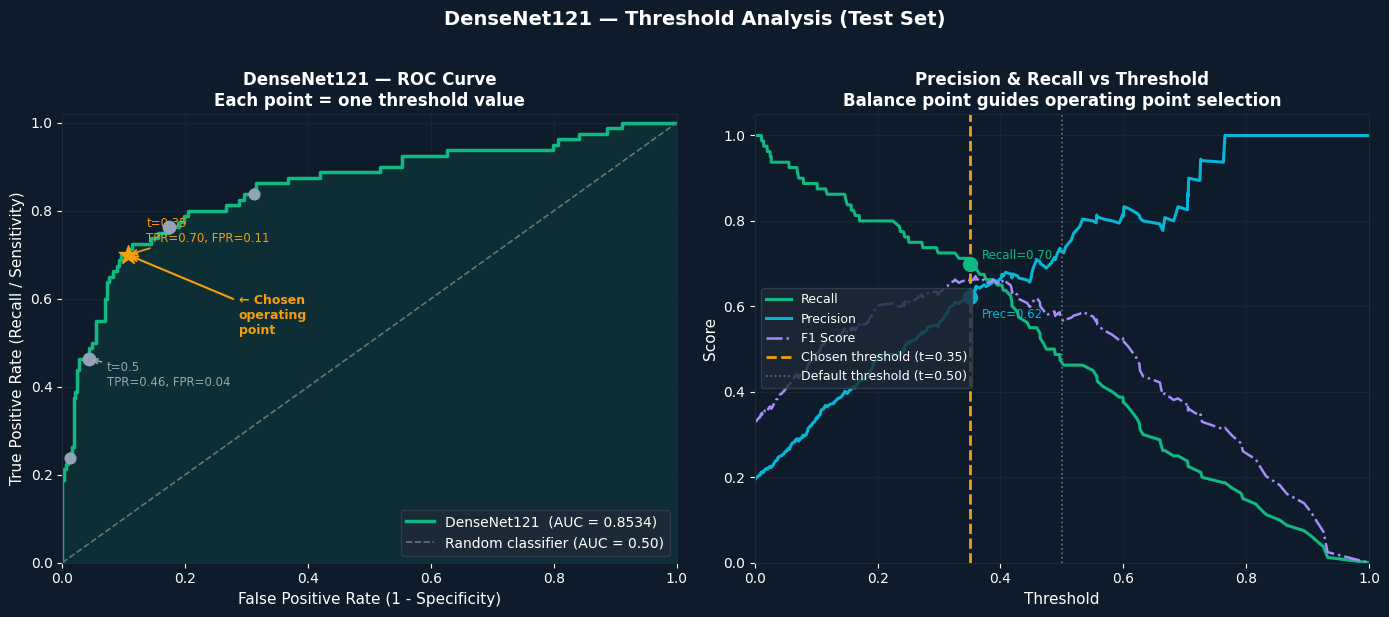

Saved. AUC-ROC: 0.8534


In [19]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

fpr, tpr, thresholds_roc = roc_curve(y_true, y_prob)
roc_auc = auc(fpr, tpr)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.patch.set_facecolor('#0D1B2A')

# ── LEFT: ROC Curve ──────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor('#0D1B2A')

# Shaded area
ax.fill_between(fpr, tpr, alpha=0.12, color='#10B981')

# The ROC curve — every point is a different threshold
ax.plot(fpr, tpr, color='#10B981', linewidth=2.5,
        label=f'DenseNet121  (AUC = {roc_auc:.4f})')

# Random baseline
ax.plot([0,1],[0,1], color='#64748B', linewidth=1.2,
        linestyle='--', label='Random classifier (AUC = 0.50)')

# Mark several threshold values along the curve
mark_thresholds = [0.7, 0.5, 0.35, 0.25, 0.15]
colors_t = ['#94A3B8', '#94A3B8', '#F59E0B', '#94A3B8', '#94A3B8']
sizes_t  = [60, 80, 200, 80, 60]

for thresh, col, sz in zip(mark_thresholds, colors_t, sizes_t):
    idx = np.argmin(np.abs(thresholds_roc - thresh))
    ax.scatter(fpr[idx], tpr[idx], color=col, s=sz,
               zorder=6, marker='o' if thresh != 0.35 else '*')
    if thresh in [0.5, 0.35]:
        offset_x = 0.03
        offset_y = -0.06 if thresh == 0.5 else 0.03
        label_txt = (f't={thresh}\n'
                     f'TPR={tpr[idx]:.2f}, FPR={fpr[idx]:.2f}')
        ax.annotate(label_txt,
                    xy=(fpr[idx], tpr[idx]),
                    xytext=(fpr[idx]+offset_x, tpr[idx]+offset_y),
                    color=col, fontsize=8.5,
                    arrowprops=dict(arrowstyle='->', color=col, lw=1.2))

# Annotate the chosen threshold prominently
idx_opt = np.argmin(np.abs(thresholds_roc - 0.35))
ax.annotate('← Chosen\noperating\npoint',
            xy=(fpr[idx_opt], tpr[idx_opt]),
            xytext=(fpr[idx_opt]+0.18, tpr[idx_opt]-0.18),
            color='#F59E0B', fontsize=9, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color='#F59E0B', lw=1.5))

ax.set_xlabel('False Positive Rate (1 - Specificity)',
              color='white', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)',
              color='white', fontsize=11)
ax.set_title('DenseNet121 — ROC Curve\nEach point = one threshold value',
             color='white', fontsize=12, fontweight='bold')
ax.tick_params(colors='white')
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
for sp in ax.spines.values(): sp.set_color('#1F2937')
ax.grid(True, color='#1F2937', linewidth=0.8, alpha=0.7)
ax.legend(loc='lower right', facecolor='#1F2937',
          edgecolor='#374151', labelcolor='white', fontsize=10)

# ── RIGHT: Precision-Recall vs Threshold ────────────────────────────
ax2 = axes[1]
ax2.set_facecolor('#0D1B2A')

# Compute precision and recall at every threshold
precisions, recalls, thresh_pr = precision_recall_curve(y_true, y_prob)
# thresh_pr has one fewer element than precisions/recalls
thresh_plot = np.append(thresh_pr, 1.0)

ax2.plot(thresh_plot, recalls, color='#10B981', linewidth=2.2,
         label='Recall')
ax2.plot(thresh_plot, precisions, color='#06B6D4', linewidth=2.2,
         label='Precision')

# F1 at each threshold
f1_scores = np.where((precisions + recalls) > 0,
                     2*precisions*recalls/(precisions+recalls), 0)
ax2.plot(thresh_plot, f1_scores, color='#A78BFA', linewidth=1.8,
         linestyle='-.', label='F1 Score')

# Mark chosen threshold
ax2.axvline(x=0.35, color='#F59E0B', linewidth=2,
            linestyle='--', label='Chosen threshold (t=0.35)')
ax2.axvline(x=0.50, color='#64748B', linewidth=1.2,
            linestyle=':', label='Default threshold (t=0.50)')

# Annotate crossing point at t=0.35
idx_35 = np.argmin(np.abs(thresh_plot - 0.35))
ax2.scatter([0.35], [recalls[idx_35]], color='#10B981', s=100, zorder=5)
ax2.scatter([0.35], [precisions[idx_35]], color='#06B6D4', s=100, zorder=5)
ax2.text(0.37, recalls[idx_35]+0.01,
         f'Recall={recalls[idx_35]:.2f}',
         color='#10B981', fontsize=8.5)
ax2.text(0.37, precisions[idx_35]-0.05,
         f'Prec={precisions[idx_35]:.2f}',
         color='#06B6D4', fontsize=8.5)

ax2.set_xlabel('Threshold', color='white', fontsize=11)
ax2.set_ylabel('Score', color='white', fontsize=11)
ax2.set_title('Precision & Recall vs Threshold\nBalance point guides operating point selection',
              color='white', fontsize=12, fontweight='bold')
ax2.tick_params(colors='white')
ax2.set_xlim([0, 1]); ax2.set_ylim([0, 1.05])
for sp in ax2.spines.values(): sp.set_color('#1F2937')
ax2.grid(True, color='#1F2937', linewidth=0.8, alpha=0.7)
ax2.legend(loc='center left', facecolor='#1F2937',
           edgecolor='#374151', labelcolor='white', fontsize=9)

plt.suptitle('DenseNet121 — Threshold Analysis (Test Set)',
             color='white', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/densenet121_roc_and_threshold.png',
            dpi=150, bbox_inches='tight', facecolor='#0D1B2A')
plt.show()
print(f"Saved. AUC-ROC: {roc_auc:.4f}")

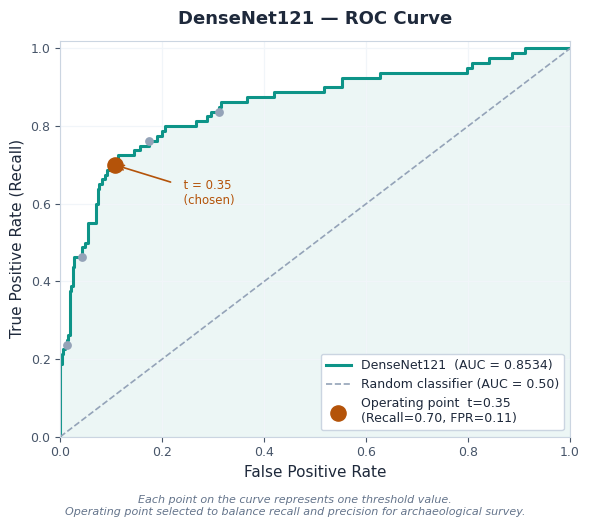

AUC-ROC: 0.8534 — Saved.


In [20]:
fig, ax = plt.subplots(figsize=(6, 5))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Shaded area under curve
ax.fill_between(fpr, tpr, alpha=0.08, color='#0D9488')

# ROC curve
ax.plot(fpr, tpr, color='#0D9488', linewidth=2.2,
        label=f'DenseNet121  (AUC = {roc_auc:.4f})')

# Random baseline
ax.plot([0,1],[0,1], color='#94A3B8', linewidth=1.2,
        linestyle='--', label='Random classifier (AUC = 0.50)')

# Mark several thresholds along the curve — small grey dots
for thresh in [0.7, 0.5, 0.25, 0.15]:
    idx = np.argmin(np.abs(thresholds_roc - thresh))
    ax.scatter(fpr[idx], tpr[idx], color='#94A3B8',
               s=40, zorder=5, linewidths=0)

# Chosen operating point — highlighted
idx_opt = np.argmin(np.abs(thresholds_roc - 0.35))
ax.scatter(fpr[idx_opt], tpr[idx_opt],
           color='#B45309', s=120, zorder=7,
           label=f'Operating point  t=0.35\n'
                 f'(Recall={tpr[idx_opt]:.2f}, FPR={fpr[idx_opt]:.2f})')
ax.annotate('  t = 0.35\n  (chosen)',
            xy=(fpr[idx_opt], tpr[idx_opt]),
            xytext=(fpr[idx_opt]+0.12, tpr[idx_opt]-0.1),
            color='#B45309', fontsize=8.5,
            arrowprops=dict(arrowstyle='->', color='#B45309', lw=1.2))

# Labels & formatting
ax.set_xlabel('False Positive Rate', color='#1E293B', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall)', color='#1E293B', fontsize=11)
ax.set_title('DenseNet121 — ROC Curve', color='#1E293B',
             fontsize=13, fontweight='bold', pad=12)
ax.tick_params(colors='#475569', labelsize=9)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])

for sp in ax.spines.values():
    sp.set_color('#CBD5E1')
    sp.set_linewidth(0.8)

ax.grid(True, color='#F1F5F9', linewidth=0.9)
ax.legend(loc='lower right', facecolor='white',
          edgecolor='#CBD5E1', fontsize=9,
          framealpha=1, labelcolor='#1E293B')

# Caption note
fig.text(0.5, -0.04,
         'Each point on the curve represents one threshold value.\n'
         'Operating point selected to balance recall and precision '
         'for archaeological survey.',
         ha='center', color='#64748B', fontsize=8, style='italic')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/densenet121_roc_curve.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f"AUC-ROC: {roc_auc:.4f} — Saved.")

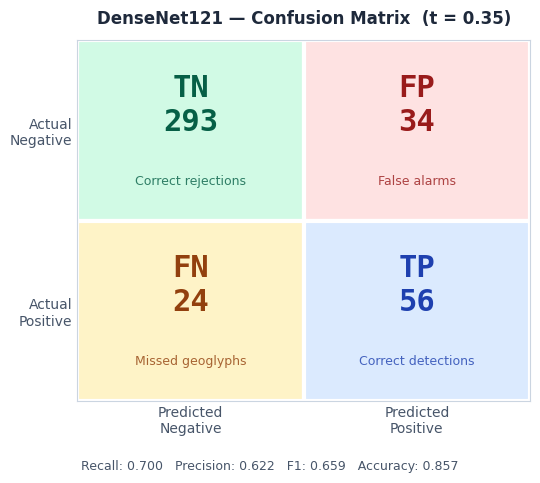

Saved.


In [22]:
fig, ax = plt.subplots(figsize=(5.5, 4.8))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Light pastel cell colors
cell_colors = [['#D1FAE5', '#FEE2E2'],   # TN=green, FP=red
               ['#FEF3C7', '#DBEAFE']]    # FN=amber, TP=blue
cell_labels = [[f'TN\n{tn}', f'FP\n{fp}'],
               [f'FN\n{fn}', f'TP\n{tp}']]
cell_subs   = [['Correct rejections', 'False alarms'],
               ['Missed geoglyphs',   'Correct detections']]
text_colors = [['#065F46', '#991B1B'],
               ['#92400E', '#1E40AF']]

for i in range(2):
    for j in range(2):
        ax.add_patch(plt.Rectangle(
            [j, 1-i], 1, 1,
            facecolor=cell_colors[i][j],
            edgecolor='white', linewidth=3))
        ax.text(j+0.5, 1-i+0.64,
                cell_labels[i][j],
                ha='center', va='center',
                fontsize=22, fontweight='bold',
                color=text_colors[i][j],
                fontfamily='monospace')
        ax.text(j+0.5, 1-i+0.22,
                cell_subs[i][j],
                ha='center', va='center',
                fontsize=9, color=text_colors[i][j],
                alpha=0.8)

ax.set_xlim(0, 2); ax.set_ylim(0, 2)
ax.set_xticks([0.5, 1.5])
ax.set_yticks([0.5, 1.5])
ax.set_xticklabels(['Predicted\nNegative', 'Predicted\nPositive'],
                    color='#1E293B', fontsize=10)
ax.set_yticklabels(['Actual\nPositive', 'Actual\nNegative'],
                    color='#1E293B', fontsize=10)
ax.tick_params(colors='#475569', length=0)
for sp in ax.spines.values():
    sp.set_color('#CBD5E1')
    sp.set_linewidth(0.8)

ax.set_title(f'DenseNet121 — Confusion Matrix  (t = {OPTIMAL_THRESHOLD})',
             color='#1E293B', fontsize=12,
             fontweight='bold', pad=12)

fig.text(0.5, 0.01,
    f'Recall: {recall:.3f}   Precision: {precision:.3f}   '
    f'F1: {f1:.3f}   Accuracy: {(tp+tn)/len(y_true):.3f}',
    ha='center', color='#475569', fontsize=9)

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(f'{PLOT_DIR}/densenet121_confusion_matrix.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved.")

Total missed geoglyphs (FN): 24 of 80


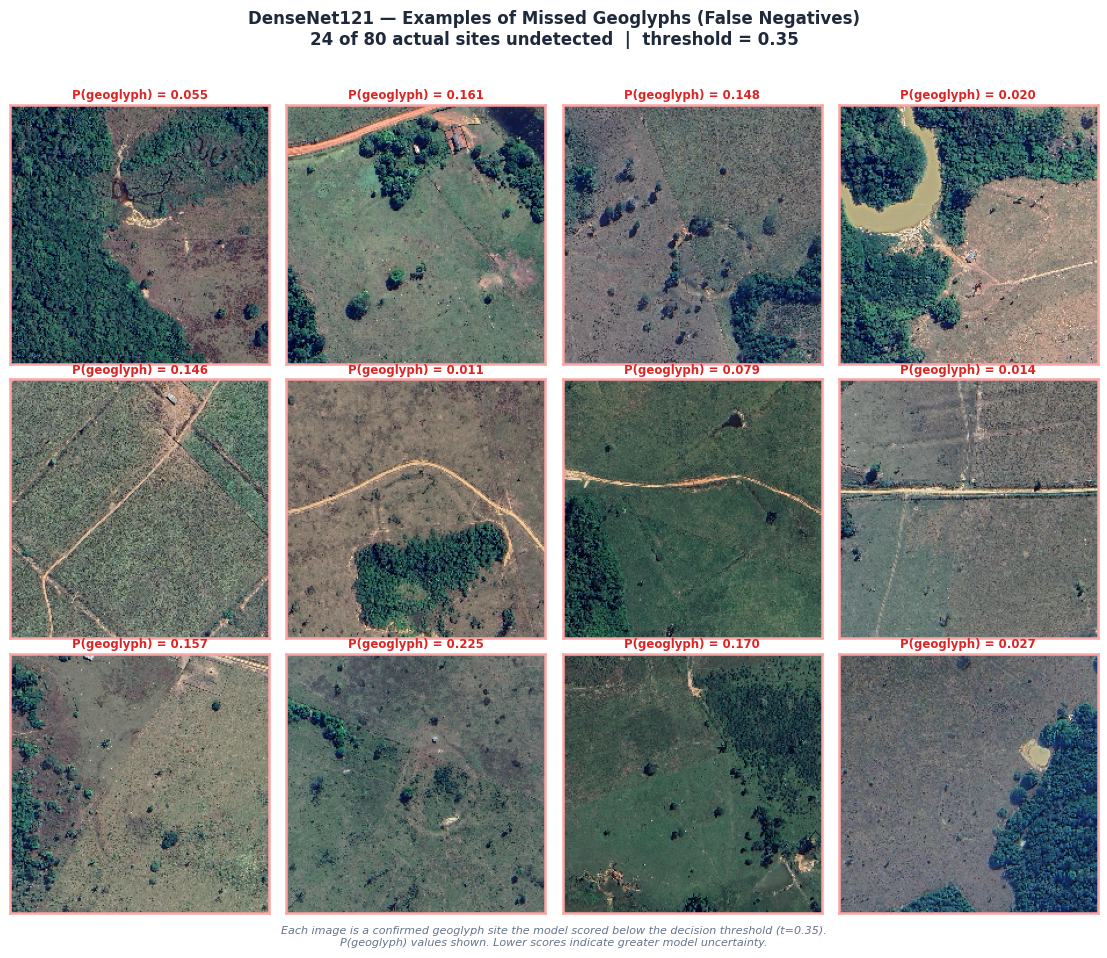

Saved — 12 missed geoglyph images.


In [23]:
# ── False Negative Visualization — Poster Ready ───────────────────
fn_paths, fn_probs = [], []
idx = 0
for path, label in zip(test_df['filepath'].values,
                        test_df['label'].values):
    if idx >= len(y_true): break
    if label == 1 and y_pred_opt[idx] == 0:
        fn_paths.append(path)
        fn_probs.append(float(y_prob[idx]))
    if int(label) == int(y_true[idx]):
        idx += 1

print(f"Total missed geoglyphs (FN): {len(fn_paths)} of {int(y_true.sum())}")

# ── Layout ────────────────────────────────────────────────────────
n_show = min(12, len(fn_paths))  # show up to 12 — 3 rows of 4
cols   = 4
rows   = (n_show + cols - 1) // cols

fig, axes = plt.subplots(rows, cols,
                          figsize=(cols * 2.8, rows * 3.0))
fig.patch.set_facecolor('white')

fig.suptitle(
    f'DenseNet121 — Examples of Missed Geoglyphs (False Negatives)\n'
    f'{len(fn_paths)} of {int(y_true.sum())} actual sites undetected  '
    f'|  threshold = {OPTIMAL_THRESHOLD}',
    color='#1E293B', fontsize=12, fontweight='bold', y=1.02)

axes_flat = axes.flatten() if hasattr(axes, 'flatten') else [axes]

for i, ax in enumerate(axes_flat):
    ax.set_facecolor('#F8FAFC')
    if i < n_show:
        try:
            raw   = tf.io.read_file(fn_paths[i])
            image = tf.image.decode_image(raw, channels=3,
                                          expand_animations=False)
            image = tf.image.resize(image, [224, 224])
            image = tf.cast(image, tf.uint8).numpy()
            ax.imshow(image)

            # Subtitle: model confidence score
            ax.set_title(f'P(geoglyph) = {fn_probs[i]:.3f}',
                         color='#DC2626', fontsize=8.5,
                         fontweight='bold', pad=4)

            # Thin red border
            for sp in ax.spines.values():
                sp.set_edgecolor('#FCA5A5')
                sp.set_linewidth(1.8)
        except:
            ax.text(0.5, 0.5, 'Load error',
                    ha='center', va='center',
                    color='#94A3B8', fontsize=8,
                    transform=ax.transAxes)
            for sp in ax.spines.values():
                sp.set_visible(False)
    else:
        ax.set_visible(False)

    ax.set_xticks([]); ax.set_yticks([])

# Caption below the grid
fig.text(
    0.5, -0.02,
    'Each image is a confirmed geoglyph site the model scored below '
    f'the decision threshold (t={OPTIMAL_THRESHOLD}).\n'
    'P(geoglyph) values shown. Lower scores indicate greater model uncertainty.',
    ha='center', color='#64748B', fontsize=8, style='italic')

plt.tight_layout()
plt.savefig(f'{PLOT_DIR}/densenet121_false_negatives_poster.png',
            dpi=200, bbox_inches='tight', facecolor='white')
plt.show()
print(f"Saved — {n_show} missed geoglyph images.")